# DensGNN: minpts × embedding encoder

Compare **GAT, GCN, and GraphSAGE** as minpts changes on **Cora, CiteSeer, and PolBlogs**.
Each dataset has its own figure with four metric panels (NMI, ARI, ACC, F1-macro), each containing
three curves, one per encoder. Change `METRICS` below to plot other recorded metrics.

This notebook reads existing results from `results/ablation_minpts_encoder` and the corresponding
YAMLs in `configs/ablation_minpts_encoder`; it does not train models or recalculate scores.
Run all cells from the repository root, `scripts/`, or `scripts/notebooks/`.

Here **minpts varies both `mrd_k` and `hdbscan_min_samples` together**, as recorded in the experiment
configs. The `sageconv` directory uses `encoder_type: sage` (GraphSAGE).
Lines connect observed points; they are not fitted curves. With repeated seeds, points
show the mean and shaded bands show ±1 sample standard deviation. A single seed has no band.

In [1]:
from pathlib import Path
import math
import warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import yaml
from IPython.display import display


def find_repo_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs/ablation_minpts_encoder").is_dir():
            return candidate
    raise FileNotFoundError("Run from the repository root, scripts/, or scripts/notebooks/.")


ROOT = find_repo_root()
CONFIG_DIR = ROOT / "configs/ablation_minpts_encoder"
RESULTS_DIR = ROOT / "results/ablation_minpts_encoder"
EXPORT_DIR = RESULTS_DIR / "analysis"
DATASETS = ["cora", "citeseer", "polblogs"]
ENCODERS = ["gat", "gcn", "sageconv"]
ENCODER_TYPES = {"gat": "gat", "gcn": "gcn", "sageconv": "sage"}
METRICS = ["nmi", "ari", "acc", "f1_macro", "silhouette"]
# Other recorded metrics: f1_micro, modularity, n_clusters, runtime_seconds,
# silhouette, calinski_harabasz, davies_bouldin, dbcv.
SAVE_EXPORTS = True  # Saves PNG/PDF figures and summary tables under analysis/.

DATASET_NAMES = {"cora": "Cora", "citeseer": "CiteSeer", "polblogs": "PolBlogs"}
ENCODER_NAMES = {"gat": "GAT", "gcn": "GCN", "sageconv": "GraphSAGE"}
METRIC_NAMES = {"nmi": "NMI", "ari": "ARI", "acc": "ACC", "f1_macro": "F1-macro",
                "f1_micro": "F1-micro", "modularity": "Modularity", "n_clusters": "Number of clusters",
                "runtime_seconds": "Runtime (s)", "silhouette": "Silhouette",
                "calinski_harabasz": "Calinski–Harabasz", "davies_bouldin": "Davies–Bouldin",
                "dbcv": "DBCV"}
COLORS = {"gat": "#0072B2", "gcn": "#D55E00", "sageconv": "#009E73"}
MARKERS = {"gat": "o", "gcn": "s", "sageconv": "^"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
figures = {}
print("Results:", RESULTS_DIR)


Results: /home/gmessias/NodeClusteringAlgorithms/results/ablation_minpts_encoder


## Load results and check coverage

Read only `runs/*/metrics.csv` for settings described by the YAMLs, avoiding aggregate CSVs and
analysis exports. Validate each run against its saved metadata. If a setting is rerun, retain the
latest successful attempt per dataset/encoder/minpts/seed; all attempts remain in `attempts`.
Failures and missing expected seeds are reported below. Nonfinite metric values remain missing,
never zero. Seeds not listed in the current config are reported and excluded.

In [2]:
specs, records, issues = [], [], []
for dataset in DATASETS:
    for encoder in ENCODERS:
        paths = sorted((CONFIG_DIR / dataset / encoder).glob("minpts_*.yaml"))
        if not paths:
            raise FileNotFoundError(f"No configs for {dataset}/{encoder}")
        for path in paths:
            cfg = yaml.safe_load(path.read_text())
            exp = cfg["experiment"]
            params = cfg["models"]["densgnn"]["params"]
            minpts = int(params["mrd_k"])
            if params["encoder_type"] != ENCODER_TYPES[encoder] or int(params["hdbscan_min_samples"]) != minpts:
                raise ValueError(f"Unexpected encoder/minpts in {path}")
            expected_seeds = list(range(int(exp["seed"]), int(exp["seed"]) + int(exp["runs"])))
            specs.append(dict(dataset=dataset, encoder=encoder, minpts=minpts, seeds=expected_seeds))
            csv_name = cfg.get("output", {}).get("csv_filename", "metrics.csv")
            for csv_path in sorted((RESULTS_DIR / exp["dataset"] / "runs").glob(f"*/{csv_name}")):
                frame = pd.read_csv(csv_path)
                for row in frame.to_dict("records"):
                    if row["model"] != "densgnn":
                        continue
                    if row["dataset"] != exp["dataset"] or str(row["run_id"]) != csv_path.parent.name:
                        raise ValueError(f"CSV identifiers do not match its path: {csv_path}")
                    seed = int(row["seed"])
                    if seed not in expected_seeds:
                        issues.append(dict(file=str(csv_path.relative_to(ROOT)), reason=f"Unexpected seed {seed}"))
                        continue
                    metadata_path = csv_path.parent / "densgnn/metadata.yaml"
                    metadata = yaml.safe_load(metadata_path.read_text())
                    saved = metadata["model_params"]
                    if (saved["encoder_type"] != ENCODER_TYPES[encoder] or int(saved["mrd_k"]) != minpts
                            or int(saved["hdbscan_min_samples"]) != minpts
                            or int(metadata["seed"]) != seed):
                        raise ValueError(f"Config/metadata mismatch: {metadata_path}")
                    records.append({**row, "dataset": dataset, "encoder": encoder,
                                    "minpts": minpts, "seed": seed,
                                    "metrics_file": str(csv_path.relative_to(ROOT))})

if not records:
    raise ValueError("No result rows found.")
attempts = pd.DataFrame(records)
unknown_metrics = set(METRICS) - set(attempts.columns)
if not METRICS or unknown_metrics:
    raise ValueError(f"Choose recorded metrics; unknown: {unknown_metrics}")
for metric in METRICS:
    attempts[metric] = pd.to_numeric(attempts[metric], errors="coerce").replace([np.inf, -np.inf], np.nan)
keys = ["dataset", "encoder", "minpts", "seed"]
successful = attempts.loc[attempts.status.eq("success")].sort_values("run_id")
data = successful.drop_duplicates(keys, keep="last").copy()
failures = attempts.loc[~attempts.status.eq("success")]
print(f"{len(attempts)} attempts; {len(data)} selected successes; {len(failures)} failures; "
      f"{len(successful) - len(data)} superseded successful attempts.")
if not failures.empty:
    display(failures[keys + ["run_id", "status", "error"]])
if issues:
    display(pd.DataFrame(issues))
if data.empty:
    raise ValueError("No successful executions available to plot.")

coverage_rows = []
for spec in specs:
    subset = data[(data.dataset == spec["dataset"]) & (data.encoder == spec["encoder"])
                  & (data.minpts == spec["minpts"])]
    coverage_rows.append({k: spec[k] for k in ["dataset", "encoder", "minpts"]} |
                         {"successful_seeds": len(subset), "expected_seeds": len(spec["seeds"]),
                          "missing_seeds": sorted(set(spec["seeds"]) - set(subset.seed))})
coverage = pd.DataFrame(coverage_rows)
display(coverage.groupby(["dataset", "encoder"])[["successful_seeds", "expected_seeds"]].sum())
incomplete = coverage.loc[coverage.missing_seeds.map(bool)]
if not incomplete.empty:
    warnings.warn("Incomplete grid: inspect the missing seeds below.")
    display(incomplete)
print("Selected seeds:", sorted(data.seed.unique()))
print("Missing metric values:", data[METRICS].isna().sum().to_dict())


270 attempts; 270 selected successes; 0 failures; 0 superseded successful attempts.


successful_seeds  expected_seeds
dataset  encoder                                   
citeseer gat                     30              30
         gcn                     30              30
         sageconv                30              30
cora     gat                     30              30
         gcn                     30              30
         sageconv                30              30
polblogs gat                     30              30
         gcn                     30              30
         sageconv                30              30

Selected seeds: [np.int64(2030)]
Missing metric values: {'nmi': 0, 'ari': 0, 'acc': 0, 'f1_macro': 0, 'silhouette': 0}


## Curves per dataset

All panels use minpts on the horizontal axis and the metric's original scale on the vertical axis.
Missing settings create gaps. Colors and markers identify the same encoder in every figure.
Values are aggregated across seeds only within the same dataset, encoder, and minpts setting.
Internal geometry scores (if selected) describe each encoder's embedding space.

In [10]:
summary = data.groupby(["dataset", "encoder", "minpts"])[METRICS].agg(["mean", "std", "count"])
summary.columns.names = ["metric", "statistic"]


def plot_dataset(dataset):
    ncols = min(2, len(METRICS))
    nrows = math.ceil(len(METRICS) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.8 * nrows), squeeze=False)
    x = np.array(sorted({s["minpts"] for s in specs if s["dataset"] == dataset}))
    for ax, metric in zip(axes.flat, METRICS):
        for encoder in ENCODERS:
            index = pd.MultiIndex.from_product([[dataset], [encoder], x],
                                               names=["dataset", "encoder", "minpts"])
            stats = summary[metric].reindex(index)
            mean = stats["mean"].to_numpy(float)
            std = stats["std"].to_numpy(float)
            ax.plot(x, mean, marker=MARKERS[encoder], markersize=3.5, linewidth=1.8,
                    color=COLORS[encoder], label=ENCODER_NAMES[encoder])
            ax.fill_between(x, mean - std, mean + std, color=COLORS[encoder], alpha=0.15)
        ax.set(xlabel="minpts (mrd_k = hdbscan_min_samples)",
               ylabel=METRIC_NAMES.get(metric, metric), title=METRIC_NAMES.get(metric, metric))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
        ax.grid(alpha=0.22)
        ax.legend(frameon=False)
    for ax in list(axes.flat)[len(METRICS):]:
        ax.set_visible(False)
    fig.suptitle(f"{DATASET_NAMES[dataset]} — minpts × encoder", fontsize=15)
    fig.tight_layout()
    figures[dataset] = fig
    plt.show()


### Cora

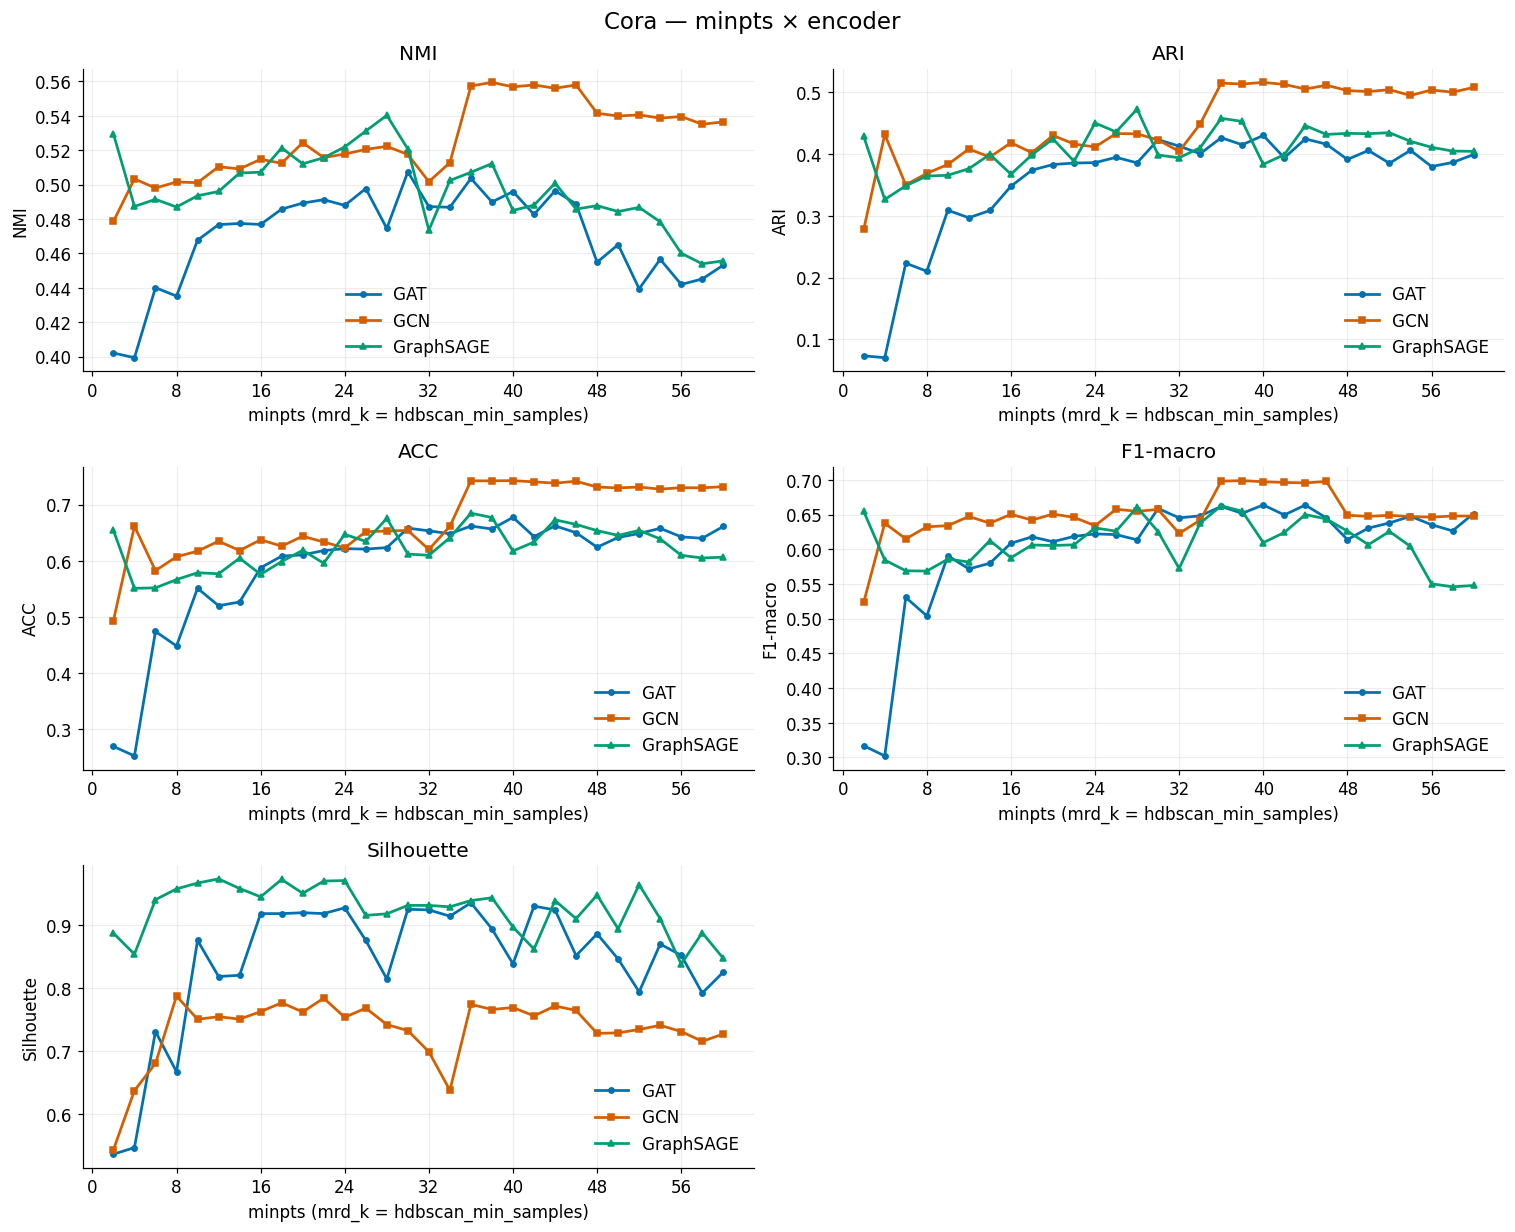

In [11]:
plot_dataset("cora")

### CiteSeer

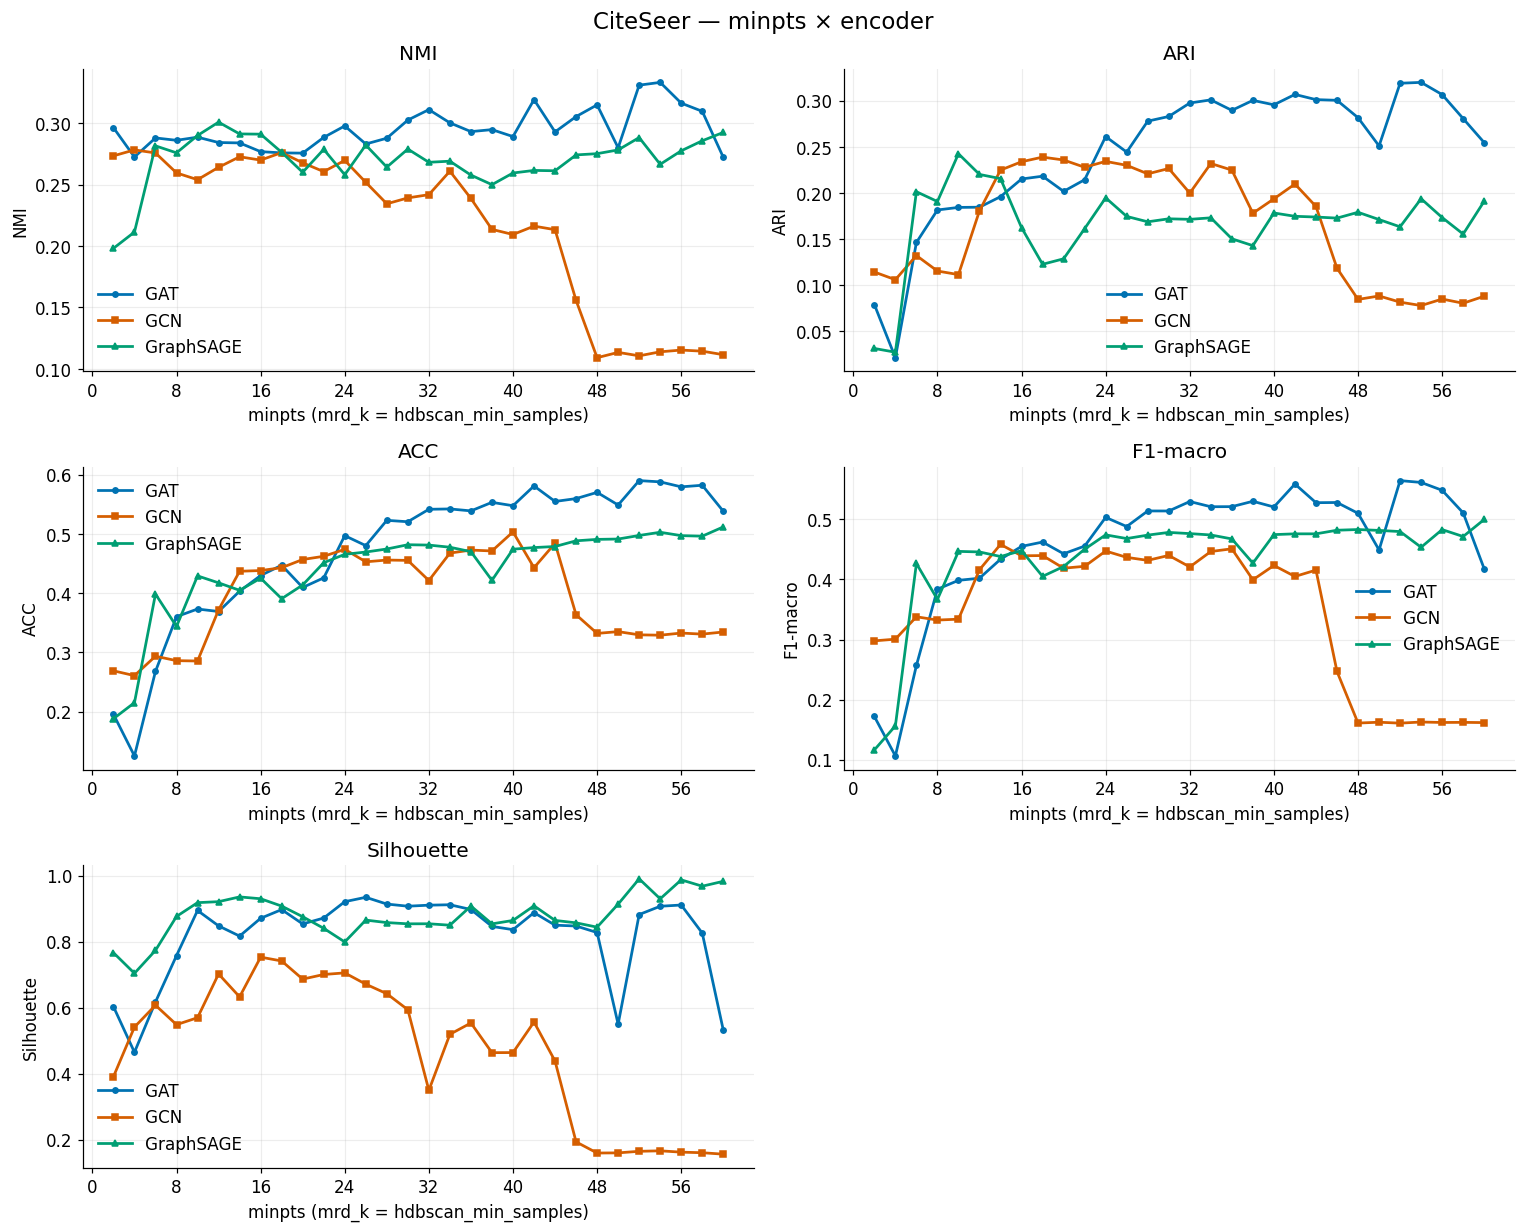

In [12]:
plot_dataset("citeseer")

### PolBlogs

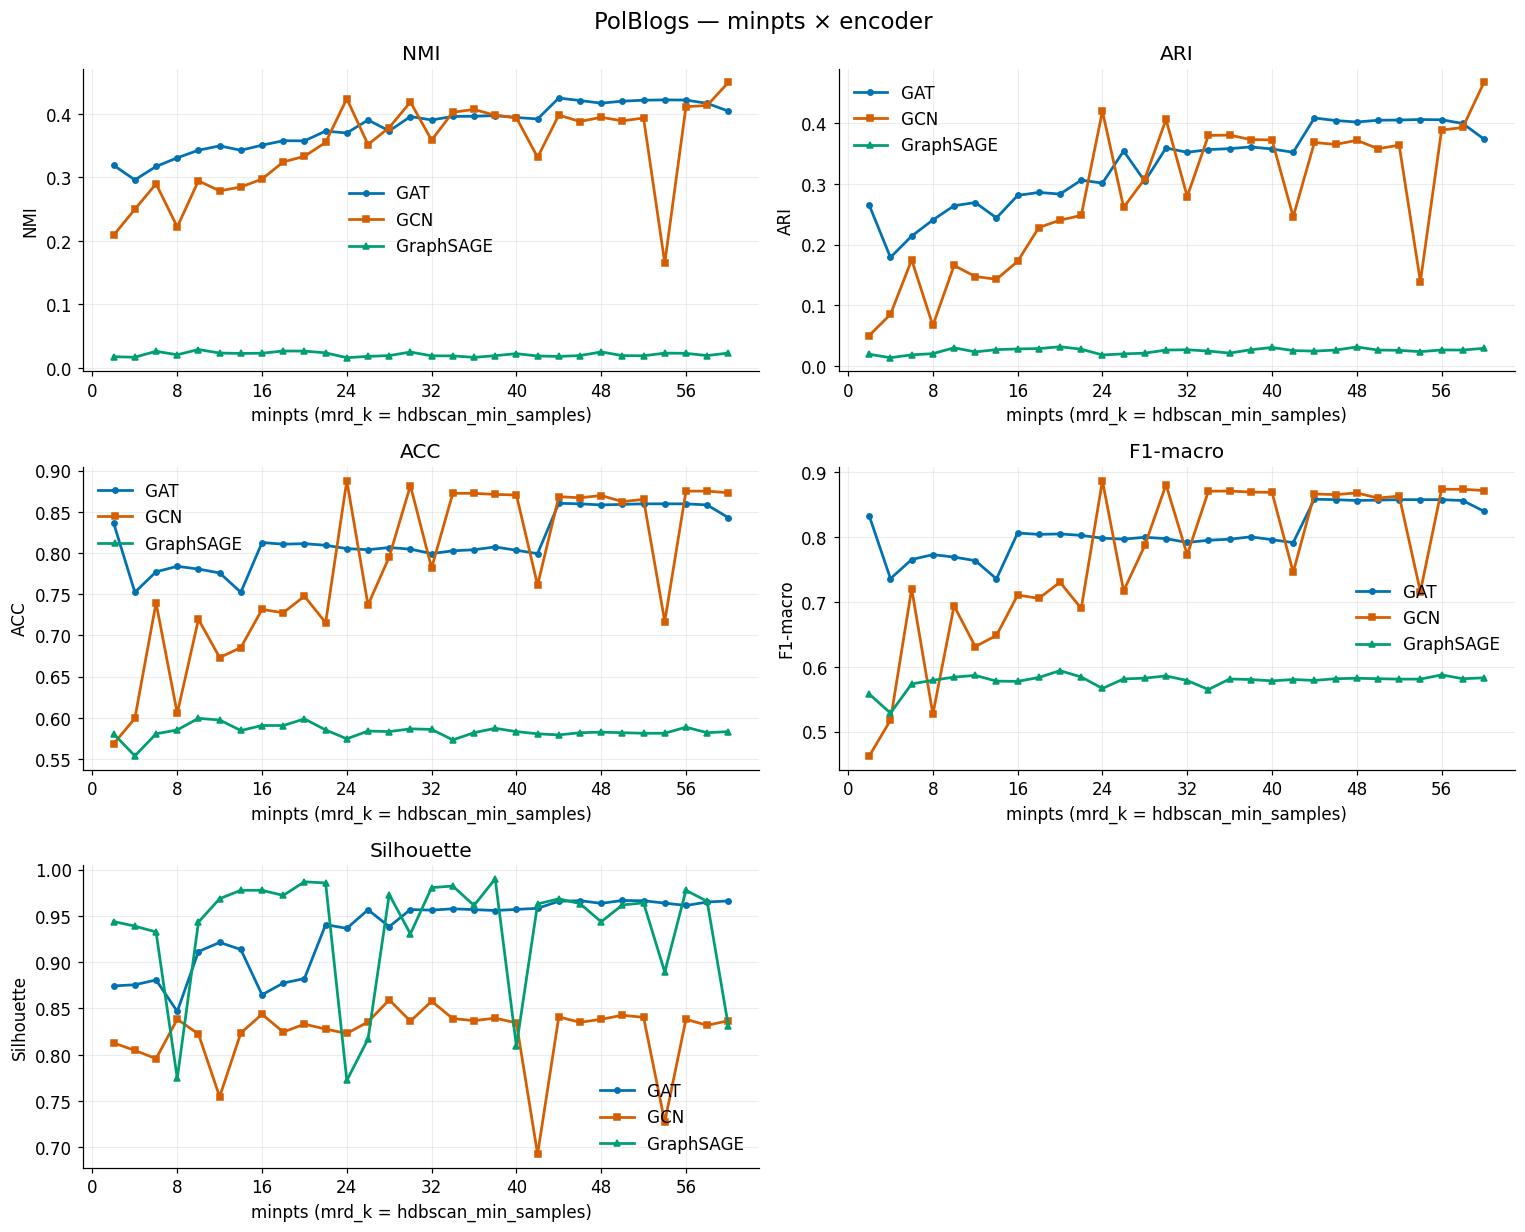

In [13]:
plot_dataset("polblogs")

## Export

When `SAVE_EXPORTS=True`, save the figures as PNG and PDF, along with the selected executions,
per-setting summary, and coverage tables in `results/ablation_minpts_encoder/analysis/`.
Existing experiment outputs are preserved. Rerunning this cell updates only the analysis exports.

In [14]:
if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    data.to_csv(EXPORT_DIR / "selected_executions.csv", index=False)
    coverage.to_csv(EXPORT_DIR / "coverage.csv", index=False)
    flat_summary = summary.copy()
    flat_summary.columns = [f"{metric}_{stat}" for metric, stat in flat_summary.columns]
    flat_summary.to_csv(EXPORT_DIR / "summary_by_minpts_encoder.csv")
    for dataset, fig in figures.items():
        for extension in ["png", "pdf"]:
            fig.savefig(EXPORT_DIR / f"{dataset}_minpts_encoder.{extension}", dpi=200, bbox_inches="tight")
    print("Exported figures and tables to:", EXPORT_DIR)
else:
    print("Exports disabled; figures are embedded in this notebook.")


Exported figures and tables to: /home/gmessias/NodeClusteringAlgorithms/results/ablation_minpts_encoder/analysis


## TikZ / PGFPlots figure for a selected metric

Set **`METRIC`** in the final cell to `"NMI"`, `"Silhouette"`, `"F1"`, `"F1-micro"`, `"ARI"`,
`"ACC"`, `"modularity"`, or another recorded metric, then rerun that cell. Names are case insensitive;
**`"F1"` means F1-macro**. This selection is independent of `METRICS` used by the Matplotlib figures.
Run the loading cells first.

The generated figure contains three vertically stacked panels (**Cora, CiteSeer, PolBlogs**),
with **GCN, GAT, and GraphSAGE** curves in each panel. Points show the mean across selected
successful seeds, on the original metric scale; missing values leave gaps.

The cell prints copyable TikZ code and exposes it as `tikz_code`. With `SAVE_TIKZ=True`, it also
saves an embeddable `.tikz` snippet and a complete `.tex` document to
`results/ablation_minpts_encoder/analysis/minpts_encoder_<metric>.*`.
Paste the `.tex` document into Overleaf, or compile it with `pdflatex`. To embed the `.tikz` file
in an existing paper, add `\usepackage{pgfplots}`, `\usepgfplotslibrary{groupplots}`, and
`\pgfplotsset{compat=1.18}` to the preamble, then use `\input{minpts_encoder_nmi.tikz}`.
Generating the code requires no LaTeX installation.

Only the bottom panel displays the minpts axis label. Panel height is 2.4 cm; marker fills and
outlines explicitly match each curve color.

The minpts axis comes directly from the selected results (`data`); this cell does not depend on
`specs`. If a dataset is absent from `data`, rerun the settings and result-loading cells.

In [ ]:
# Change this value and rerun this cell; it is independent of the METRICS list above.
METRIC = "Silhouette"  # Examples: "Silhouette", "F1" (macro), "F1-micro", "ARI", "modularity".
SAVE_TIKZ = True

import re


def metric_key(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def latex_escape(value):
    replacements = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$",
                    "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}",
                    "~": r"\textasciitilde{}", "^": r"\textasciicircum{}",
                    "–": "--"}
    return "".join(replacements.get(char, char) for char in str(value))


def build_tikz(metric):
    aliases = {metric_key(name): column for column, label in METRIC_NAMES.items()
               for name in (column, label)}
    aliases.update({"f1": "f1_macro", "f1score": "f1_macro", "accuracy": "acc"})
    column = aliases.get(metric_key(metric))
    if column is None or column not in data.columns:
        raise ValueError(f"Unknown/unavailable metric {metric!r}. Choose from: "
                         f"{[name for name in METRIC_NAMES if name in data.columns]}")

    # Use the already validated, selected successful runs; average repeated seeds.
    values = data[["dataset", "encoder", "minpts", column]].copy()
    values[column] = pd.to_numeric(values[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
    # Read the x-axis from the same results as the y-axis. Other cells may overwrite specs.
    panel_datasets = ["cora", "citeseer", "polblogs"]
    values["minpts"] = pd.to_numeric(values["minpts"], errors="coerce").replace([np.inf, -np.inf], np.nan)
    x_by_dataset = {dataset: sorted(values.loc[values["dataset"].eq(dataset), "minpts"].dropna().unique())
                    for dataset in panel_datasets}
    missing = [dataset for dataset, x in x_by_dataset.items() if not x]
    if missing:
        raise ValueError(
            f"No minpts results loaded for: {', '.join(missing)}. "
            "Rerun the settings and result-loading cells before generating TikZ. "
            f"Loaded datasets: {values['dataset'].dropna().unique().tolist()}"
        )
    means = values.groupby(["dataset", "encoder", "minpts"])[column].mean()
    ylabel = latex_escape(METRIC_NAMES[column])
    lines = [
        "% Requires: \\usepackage{pgfplots} and \\usepgfplotslibrary{groupplots}",
        "% Preamble: \\pgfplotsset{compat=1.18}",
        f"% Metric: {column}; curves are means across selected successful seeds.",
        "% Missing observations are NaN gaps; no interpolation or smoothing.",
        r"\begin{tikzpicture}",
        r"\begin{groupplot}[",
        r"  group style={group size=1 by 3, vertical sep=1.0cm},",
        r"  width=12cm, height=2.4cm, scale only axis,",
        r"  font=\small, tick label style={font=\scriptsize},",
        r"  title style={font=\small},",
        f"  ylabel={{{ylabel}}},",
        r"  grid=major, grid style={gray!20},",
        r"  tick align=inside, scaled y ticks=false,",
        r"  unbounded coords=jump,",
        r"  legend style={font=\scriptsize, legend columns=3, at={(0.5,1)}, anchor=south, yshift=22pt,",
        r"                draw=gray!50, fill=white, cells={anchor=west}},",
        r"]",
    ]
    styles = {"gcn": "color=black, draw=black, dashed, mark=*, mark options={draw=black, fill=black}", "gat": "color=red, draw=red, dashed, mark=square*, mark options={draw=red, fill=red}",
              "sageconv": "color=blue!70!black, draw=blue!70!black, dashed, mark=triangle*, "
                          "mark options={draw=blue!70!black, fill=blue!70!black}"}
    for panel, dataset in enumerate(panel_datasets):
        x_values = x_by_dataset[dataset]
        xlabel = r", xlabel={minpts}" if panel == 2 else ""
        lines.append(r"\nextgroupplot[title={" + latex_escape(DATASET_NAMES[dataset])
                     + f"}}, xmin={min(x_values)}, xmax={max(x_values)}{xlabel}]")
        for encoder in ["gcn", "gat", "sageconv"]:
            index = pd.MultiIndex.from_product([[dataset], [encoder], x_values], names=means.index.names)
            y_values = means.reindex(index).to_numpy(float)
            if not np.isfinite(y_values).any():
                warnings.warn(f"No finite {column} values for {dataset}/{encoder}; curve will be empty.")
            coordinates = " ".join(
                f"({x},{y:.12g})" if np.isfinite(y) else f"({x},nan)"
                for x, y in zip(x_values, y_values)
            )
            options = styles[encoder] + ", line width=0.7pt, mark size=1.5pt"
            if panel > 0:
                options += ", forget plot"
            lines.extend([f"\\addplot[{options}] coordinates {{", f"  {coordinates}", "};"])
            if panel == 0:
                lines.append(r"\addlegendentry{" + ENCODER_NAMES[encoder] + "}")
    lines.extend([r"\end{groupplot}", r"\end{tikzpicture}"])
    return column, "\n".join(lines)


metric_column, tikz_code = build_tikz(METRIC)
# Complete document for Overleaf or pdflatex; tikz_code is the embeddable figure.
tex_document = "\n".join([
    r"\documentclass[tikz,border=5pt]{standalone}",
    r"\usepackage{pgfplots}",
    r"\usepgfplotslibrary{groupplots}",
    r"\pgfplotsset{compat=1.18}",
    r"\begin{document}", tikz_code, r"\end{document}", "",
])
if SAVE_TIKZ:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    tikz_path = EXPORT_DIR / f"minpts_encoder_{metric_column}.tikz"
    tex_path = EXPORT_DIR / f"minpts_encoder_{metric_column}.tex"
    tikz_path.write_text(tikz_code + "\n", encoding="utf-8")
    tex_path.write_text(tex_document, encoding="utf-8")
    print(f"Saved snippet: {tikz_path}\nSaved standalone document: {tex_path}\n")
print(tikz_code)


Saved snippet: /home/gmessias/NodeClusteringAlgorithms/results/ablation_minpts_encoder/analysis/minpts_encoder_silhouette.tikz
Saved standalone document: /home/gmessias/NodeClusteringAlgorithms/results/ablation_minpts_encoder/analysis/minpts_encoder_silhouette.tex

% Requires: \usepackage{pgfplots} and \usepgfplotslibrary{groupplots}
% Preamble: \pgfplotsset{compat=1.18}
% Metric: silhouette; curves are means across selected successful seeds.
% Missing observations are NaN gaps; no interpolation or smoothing.
\begin{tikzpicture}
\begin{groupplot}[
  group style={group size=1 by 3, vertical sep=1.0cm},
  width=12cm, height=2.4cm, scale only axis,
  font=\small, tick label style={font=\scriptsize},
  title style={font=\small},
  ylabel={Silhouette},
  grid=major, grid style={gray!20},
  tick align=inside, scaled y ticks=false,
  unbounded coords=jump,
  legend style={font=\scriptsize, legend columns=3, at={(0.5,1)}, anchor=south, yshift=22pt,
                draw=gray!50, fill=white, cel